# ĐỀ TÀI ĐT08: PHÂN TÍCH NHU CẦU ĐẶT PHÒNG & NGUYÊN NHÂN HỦY PHÒNG KHÁCH SẠN
**(Hotel Booking Demand & Cancellation Pipeline)**

- **Lĩnh vực:** Du lịch – Khách sạn (Hospitality & Tourism)
- **Bộ dữ liệu:** Hotel Booking Demand Dataset (`jessemostipak/hotel-booking-demand` — 119.390 dòng, 32 thuộc tính)
- **Môi trường thực thi:** Google Colab
- **Thư mục lưu trữ Google Drive:** `/content/drive/MyDrive/NTTU/NH 2026-2027/HK1 2026-2027/Chuyên đề chuyên sâu Kỹ thuật CNTT 1/DAN`
- **Cấu trúc phân công nhóm (3 thành viên):**
  - **Phần 1 (Trung Kiên - Data Engineer):** Thiết lập môi trường, nạp dữ liệu, làm sạch, chống rò rỉ dữ liệu (Data Leakage) & Feature Engineering.
  - **Phần 2 (Đăng Khoa - Data Analyst):** Phân tích khám phá dữ liệu (EDA) & trực quan hóa so sánh City Hotel vs Resort Hotel.
  - **Phần 3 & 4 (Lê Anh Khoa - ML Modeler):** Xây dựng `Scikit-Learn Pipeline`, huấn luyện & so sánh các mô hình dự đoán hủy phòng (`is_canceled`), hồi quy giá phòng (`adr`) và mô phỏng tối ưu doanh thu.

## PHẦN 0: CÀI ĐẶT THƯ VIỆN & KHỞI TẠO MÔI TRƯỜNG GOOGLE COLAB
Cell dưới đây sẽ tự động cài đặt các thư viện cần thiết (nếu thiếu trên Colab) và cấu hình hiển thị biểu đồ rõ nét.

In [1]:
# Cài đặt các thư viện bổ trợ nếu chưa có trên Google Colab
!pip install -q xgboost lightgbm shap kagglehub joblib

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Cấu hình giao diện biểu đồ
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

print("Khởi tạo môi trường và nạp thư viện thành công!")

Khởi tạo môi trường và nạp thư viện thành công!


---
## PHẦN 1 (TRUNG KIÊN): NẠP DỮ LIỆU, LÀM SẠCH & FEATURE ENGINEERING

### 1.1. Kết nối Google Drive & Nạp bộ dữ liệu tự động
Toàn bộ dữ liệu thô, dữ liệu sạch, biểu đồ và mô hình sẽ được lưu trực tiếp trong thư mục dự án của nhóm:
`/content/drive/MyDrive/NTTU/NH 2026-2027/HK1 2026-2027/Chuyên đề chuyên sâu Kỹ thuật CNTT 1/DAN`

Hàm `load_hotel_dataset()` hỗ trợ tìm file `hotel_bookings.csv` ở cả thư mục gốc `DAN/` lẫn thư mục con `DAN/data_raw/`, nếu chưa có sẽ tự động tải từ Kaggle về và lưu lại vào Drive.

In [2]:
USE_GOOGLE_DRIVE = True
BASE_DIR = "/content/drive/MyDrive/NTTU/NH 2026-2027/HK1 2026-2027/Chuyên đề chuyên sâu Kỹ thuật CNTT 1/DAN"

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        print(f"Đã kết nối Google Drive. Thư mục lưu trữ dự án:\n-> {BASE_DIR}")
    except Exception as e:
        BASE_DIR = "/content/Project_DT08_HotelBooking"
        print(f"Không thể mount Google Drive ({e}), chuyển sang lưu cục bộ tại {BASE_DIR}")

RAW_DIR = os.path.join(BASE_DIR, "data_raw")
CLEAN_DIR = os.path.join(BASE_DIR, "data_clean")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")

for folder in [BASE_DIR, RAW_DIR, CLEAN_DIR, OUTPUT_DIR]:
    os.makedirs(folder, exist_ok=True)

def load_hotel_dataset():
    direct_drive_csv = os.path.join(BASE_DIR, "hotel_bookings.csv")
    raw_drive_csv = os.path.join(RAW_DIR, "hotel_bookings.csv")
    local_csv = "/content/hotel_bookings.csv"

    # Cách 1: Kiểm tra ngay trong thư mục DAN hoặc DAN/data_raw trên Google Drive
    for path_candidate in [direct_drive_csv, raw_drive_csv]:
        if os.path.exists(path_candidate):
            print(f"[1] Đang nạp dữ liệu từ Drive: {path_candidate}")
            return pd.read_csv(path_candidate)

    # Cách 2: Kiểm tra thư mục /content
    if os.path.exists(local_csv):
        print(f"[2] Đang nạp dữ liệu cục bộ: {local_csv}")
        df_tmp = pd.read_csv(local_csv)
        df_tmp.to_csv(raw_drive_csv, index=False)
        return df_tmp

    # Cách 3: Tự động tải từ Kaggle thông qua kagglehub và sao lưu vào DAN/data_raw
    try:
        import kagglehub
        print("[3] Đang tự động tải bộ dữ liệu từ Kaggle (jessemostipak/hotel-booking-demand)...")
        dataset_path = kagglehub.dataset_download("jessemostipak/hotel-booking-demand")
        downloaded_csv = os.path.join(dataset_path, "hotel_bookings.csv")
        if os.path.exists(downloaded_csv):
            df_tmp = pd.read_csv(downloaded_csv)
            df_tmp.to_csv(raw_drive_csv, index=False)
            print(f"Tải thành công và đã sao lưu vào: {raw_drive_csv}")
            return df_tmp
    except Exception as e:
        print(f"Không thể tải tự động qua kagglehub: {e}")

    # Cách 4: Upload thủ công từ máy tính
    from google.colab import files
    print("[4] Vui lòng chọn file 'hotel_bookings.csv' từ máy tính để tải lên:")
    uploaded = files.upload()
    filename = list(uploaded.keys())[0]
    df_tmp = pd.read_csv(filename)
    df_tmp.to_csv(raw_drive_csv, index=False)
    return df_tmp

df_raw = load_hotel_dataset()
print(f"Kích thước dữ liệu gốc: {df_raw.shape[0]:,} dòng x {df_raw.shape[1]} cột")
df_raw.head(5)

Mounted at /content/drive
Đã kết nối Google Drive. Thư mục lưu trữ dự án:
-> /content/drive/MyDrive/NTTU/NH 2026-2027/HK1 2026-2027/Chuyên đề chuyên sâu Kỹ thuật CNTT 1/DAN
[3] Đang tự động tải bộ dữ liệu từ Kaggle (jessemostipak/hotel-booking-demand)...
Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
Tải thành công và đã sao lưu vào: /content/drive/MyDrive/NTTU/NH 2026-2027/HK1 2026-2027/Chuyên đề chuyên sâu Kỹ thuật CNTT 1/DAN/data_raw/hotel_bookings.csv
Kích thước dữ liệu gốc: 119,390 dòng x 32 cột


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03


### 1.2. Kiểm tra chất lượng dữ liệu gốc (Missing Values, Outliers, Duplicates)
Kiểm tra các đặc điểm quan trọng để giải trình với giảng viên:
- **Giá trị khuyết thiếu:** `company` (~94%), `agent` (~13.6%), `country` (~488 dòng), `children` (4 dòng).
- **Dòng trùng lặp (~31.994 dòng):** Không xóa vì đây là các lượt đặt phòng hợp lệ của khách đoàn hoặc nhiều khách đặt cùng hạng phòng trong cùng ngày qua cùng đại lý.
- **Dữ liệu bất hợp lý:** Đơn đặt phòng có tổng số khách = 0 hoặc `adr <= 0`, `adr > 1000`.

In [3]:
print("=== 1. THÔNG TIN CÁC CỘT & KIỂU DỮ LIỆU ===")
print(df_raw.info())

print("\n=== 2. THỐNG KÊ GIÁ TRỊ KHUYẾT THIẾU (MISSING VALUES) ===")
missing_df = pd.DataFrame({
    'So_luong_thieu': df_raw.isnull().sum(),
    'Ty_le_%': (df_raw.isnull().sum() / len(df_raw)) * 100
})
print(missing_df[missing_df['So_luong_thieu'] > 0].sort_values(by='So_luong_thieu', ascending=False))

print("\n=== 3. PHÂN PHỐI BIẾN MỤC TIÊU (is_canceled) ===")
cancel_dist = df_raw['is_canceled'].value_counts(normalize=True) * 100
print(f"Không hủy (0): {cancel_dist[0]:.2f}% ({df_raw['is_canceled'].value_counts()[0]:,} đơn)")
print(f"Có hủy    (1): {cancel_dist[1]:.2f}% ({df_raw['is_canceled'].value_counts()[1]:,} đơn)")

print(f"\n=== 4. KIỂM TRA DỮ LIỆU TRÙNG LẶP & BẤT HỢP LÝ ===")
print(f"- Số dòng trùng lặp hoàn toàn: {df_raw.duplicated().sum():,} dòng (Giữ lại vì phản ánh đặt phòng theo đoàn/cùng ngày)")
zero_guests = ((df_raw['adults'] + df_raw['children'].fillna(0) + df_raw['babies']) == 0).sum()
print(f"- Số dòng có tổng số khách = 0: {zero_guests} dòng")
print(f"- Số dòng có ADR <= 0: {(df_raw['adr'] <= 0).sum():,} dòng")
print(f"- Số dòng có ADR > 1000: {(df_raw['adr'] > 1000).sum()} dòng (Max ADR = {df_raw['adr'].max()})")

=== 1. THÔNG TIN CÁC CỘT & KIỂU DỮ LIỆU ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          11

### 1.3. Tiền xử lý & Tạo đặc trưng mới (Data Cleaning & Feature Engineering)
Các bước xử lý chuẩn hóa:
1. Điền khuyết thiếu: `children = 0`, `agent = 0` (đặt trực tiếp không qua đại lý), `country = 'Unknown'`.
2. Chuyển cột `company` (thiếu 94%) thành biến nhị phân `has_company` (`1`: đặt qua công ty bảo lãnh, `0`: cá nhân/khác).
3. Lọc bỏ các bản ghi nhiễu: `total_guests == 0`, `adr <= 0`, và `adr > 1000`.
4. Chuẩn hóa cột `meal`: gộp nhãn `'Undefined'` vào `'SC'` (*Self Catering* — tự túc ăn uống).
5. Tạo các biến đặc trưng nghiệp vụ mới:
   - `total_nights`: Tổng số đêm lưu trú (`stays_in_weekend_nights + stays_in_week_nights`).
   - `total_guests`: Tổng số khách (`adults + children + babies`).
   - `is_room_changed`: Cờ đánh dấu khách bị đổi loại phòng so với lúc đặt (`reserved_room_type != assigned_room_type`).
   - `estimated_revenue`: Doanh thu ước tính của đơn đặt phòng (`adr * total_nights`).
   - `arrival_month_num`: Số thứ tự tháng (`1` đến `12`) để sắp xếp biểu đồ và đưa vào mô hình.
   - `lead_time_group`: Phân nhóm thời gian đặt trước.
   - `country_grouped`: Giữ Top 15 quốc gia phổ biến nhất, các quốc gia còn lại gom vào `'Other'` để tối ưu hóa kích thước ma trận mã hóa.

In [4]:
df = df_raw.copy()

# 1. Xử lý giá trị khuyết thiếu
df['children'] = df['children'].fillna(0).astype(int)
df['agent'] = df['agent'].fillna(0).astype(int)
df['country'] = df['country'].fillna('Unknown')
df['has_company'] = df['company'].notnull().astype(int)

# 2. Chuẩn hóa giá trị cột meal
df['meal'] = df['meal'].replace({'Undefined': 'SC'})

# 3. Tạo đặc trưng mới (Feature Engineering)
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['is_room_changed'] = (df['reserved_room_type'] != df['assigned_room_type']).astype(int)

# 4. Lọc nhiễu & ngoại lai cực đoan
initial_rows = len(df)
df = df[df['total_guests'] > 0].copy()
df = df[df['total_nights'] > 0].copy()
df = df[(df['adr'] > 0) & (df['adr'] <= 1000)].copy()

# Tính doanh thu ước tính sau khi đã làm sạch adr và total_nights
df['estimated_revenue'] = df['adr'] * df['total_nights']

# 5. Chuyển đổi tháng sang dạng số (1-12)
month_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4,
    'May': 5, 'June': 6, 'July': 7, 'August': 8,
    'September': 9, 'October': 10, 'November': 11, 'December': 12
}
df['arrival_month_num'] = df['arrival_date_month'].map(month_map)

# 6. Phân nhóm thời gian đặt trước (lead_time_group)
bins = [-1, 7, 30, 90, 180, 1000]
labels = ['0-7 ngày', '8-30 ngày', '31-90 ngày', '91-180 ngày', '>180 ngày']
df['lead_time_group'] = pd.cut(df['lead_time'], bins=bins, labels=labels)

# 7. Gom nhóm quốc gia (Top 15 + Other)
top_15_countries = df['country'].value_counts().nlargest(15).index
df['country_grouped'] = np.where(df['country'].isin(top_15_countries), df['country'], 'Other')

# Lưu file dữ liệu sạch để dùng chung cho các thành viên
clean_csv_path = os.path.join(CLEAN_DIR, "hotel_bookings_clean.csv")
df.to_csv(clean_csv_path, index=False)

print(f"Hoàn tất làm sạch dữ liệu!")
print(f"- Số dòng trước làm sạch: {initial_rows:,}")
print(f"- Số dòng sau làm sạch : {len(df):,} (Đã loại bỏ {initial_rows - len(df):,} dòng nhiễu/ngoại lai)")
print(f"- Số thuộc tính hiện tại: {df.shape[1]} cột")
print(f"- File dữ liệu sạch đã lưu tại: {clean_csv_path}")

Hoàn tất làm sạch dữ liệu!
- Số dòng trước làm sạch: 119,390
- Số dòng sau làm sạch : 117,398 (Đã loại bỏ 1,992 dòng nhiễu/ngoại lai)
- Số thuộc tính hiện tại: 40 cột
- File dữ liệu sạch đã lưu tại: /content/drive/MyDrive/NTTU/NH 2026-2027/HK1 2026-2027/Chuyên đề chuyên sâu Kỹ thuật CNTT 1/DAN/data_clean/hotel_bookings_clean.csv


---
## PHẦN 2 (ĐĂNG KHOA): PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA) & TRỰC QUAN HÓA

### 2.1. Tổng quan quy mô đặt phòng & Tỷ lệ hủy giữa City Hotel và Resort Hotel

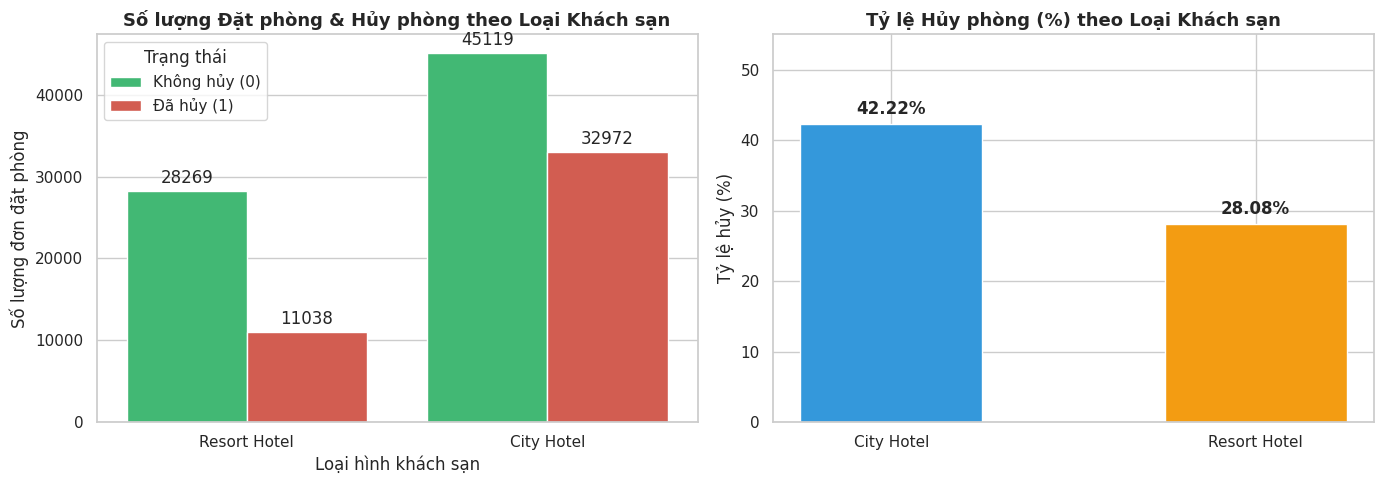

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Số lượng đơn đặt phòng theo loại khách sạn và trạng thái hủy
sns.countplot(data=df, x='hotel', hue='is_canceled', ax=axes[0], palette=['#2ecc71', '#e74c3c'])
axes[0].set_title('Số lượng Đặt phòng & Hủy phòng theo Loại Khách sạn')
axes[0].set_xlabel('Loại hình khách sạn')
axes[0].set_ylabel('Số lượng đơn đặt phòng')
axes[0].legend(title='Trạng thái', labels=['Không hủy (0)', 'Đã hủy (1)'])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=3)

# Biểu đồ 2: Tỷ lệ phần trăm hủy phòng của từng loại khách sạn
cancel_rate_hotel = df.groupby('hotel')['is_canceled'].mean() * 100
bars = axes[1].bar(cancel_rate_hotel.index, cancel_rate_hotel.values, color=['#3498db', '#f39c12'], width=0.5)
axes[1].set_title('Tỷ lệ Hủy phòng (%) theo Loại Khách sạn')
axes[1].set_ylabel('Tỷ lệ hủy (%)')
axes[1].set_ylim(0, 55)
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 1.5, f'{yval:.2f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "01_hotel_cancellation_overview.png"), dpi=300)
plt.show()

### 2.2. Xu hướng Mùa vụ: Nhu cầu Đặt phòng & Giá phòng Trung bình (ADR) theo Tháng
*(Lưu ý nghiệp vụ: Khi tính giá phòng trung bình thực tế `ADR`, chỉ tính trên các đơn **không bị hủy** `is_canceled == 0` để phản ánh đúng doanh thu thực thu).*

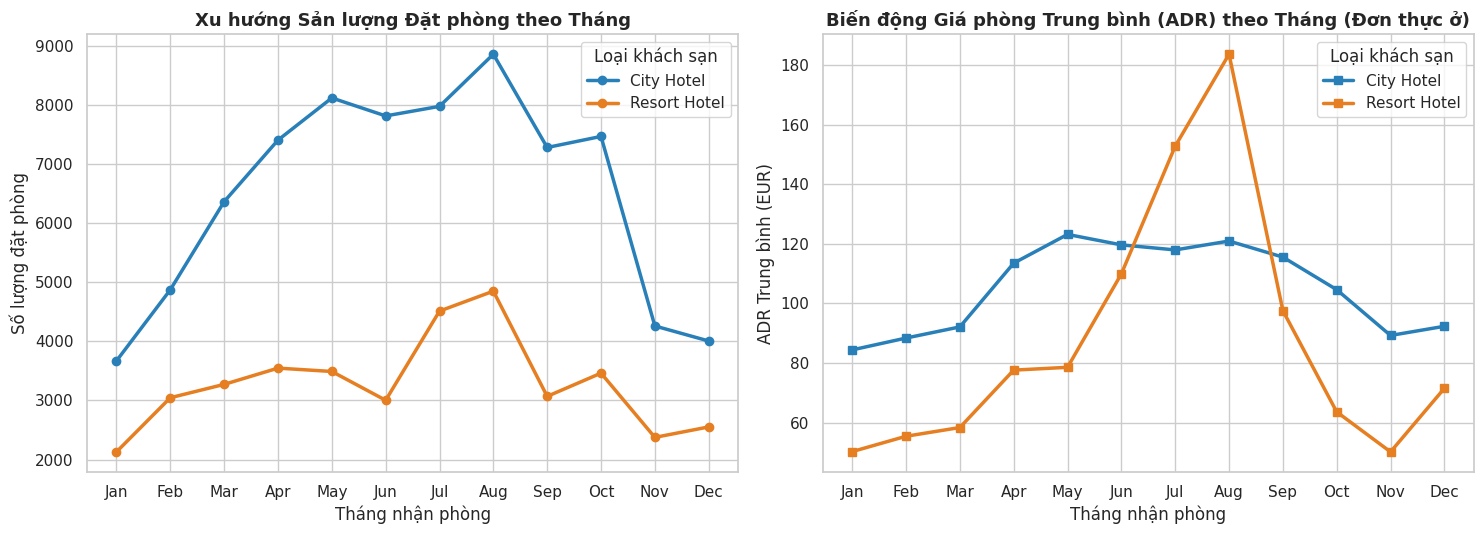

Bảng tóm tắt ADR trung bình (EUR) theo tháng (Đơn không hủy):


hotel,City Hotel,Resort Hotel
arrival_month_num,,
1,84.39,50.24
2,88.37,55.40
3,92.11,58.33
4,113.52,77.60
5,123.18,78.55
6,119.66,109.92
7,117.97,152.80
8,120.95,183.69
9,115.56,97.58


In [6]:
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Dữ liệu nhu cầu đặt phòng theo tháng (tất cả đơn)
monthly_demand = df.groupby(['arrival_month_num', 'hotel']).size().unstack()

# Dữ liệu ADR trung bình theo tháng (chỉ tính đơn không hủy)
df_not_canceled = df[df['is_canceled'] == 0]
monthly_adr = df_not_canceled.groupby(['arrival_month_num', 'hotel'])['adr'].mean().unstack()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Biểu đồ 1: Sản lượng đặt phòng theo tháng
monthly_demand.plot(kind='line', marker='o', linewidth=2.5, ax=axes[0], color=['#2980b9', '#e67e22'])
axes[0].set_title('Xu hướng Sản lượng Đặt phòng theo Tháng')
axes[0].set_xlabel('Tháng nhận phòng')
axes[0].set_ylabel('Số lượng đặt phòng')
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(month_names)
axes[0].legend(title='Loại khách sạn')

# Biểu đồ 2: Giá phòng trung bình (ADR) theo tháng
monthly_adr.plot(kind='line', marker='s', linewidth=2.5, ax=axes[1], color=['#2980b9', '#e67e22'])
axes[1].set_title('Biến động Giá phòng Trung bình (ADR) theo Tháng (Đơn thực ở)')
axes[1].set_xlabel('Tháng nhận phòng')
axes[1].set_ylabel('ADR Trung bình (EUR)')
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_names)
axes[1].legend(title='Loại khách sạn')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "02_monthly_demand_and_adr.png"), dpi=300)
plt.show()

print("Bảng tóm tắt ADR trung bình (EUR) theo tháng (Đơn không hủy):")
display(monthly_adr.round(2))

### 2.3. Phân tích Phân khúc Thị trường (Market Segment): Sản lượng, Tỷ lệ hủy & Mức chi trả ADR

,Tong_don,Ty_le_huy_pct,ADR_trung_binh,Doanh_thu_uoc_tinh
market_segment,,,,
Online TA,56089,36.94,117.99,"23,934,785.20"
Offline TA/TO,23884,34.63,88.34,"8,146,250.09"
Groups,19557,61.73,80.51,"4,669,673.50"
Direct,12361,15.40,117.70,"5,091,252.22"
Corporate,5211,18.94,70.48,"774,275.26"
Aviation,231,22.08,102.74,"87,446.36"
Complementary,63,7.94,34.04,"5,082.52"
Undefined,2,100.00,15.00,48.00


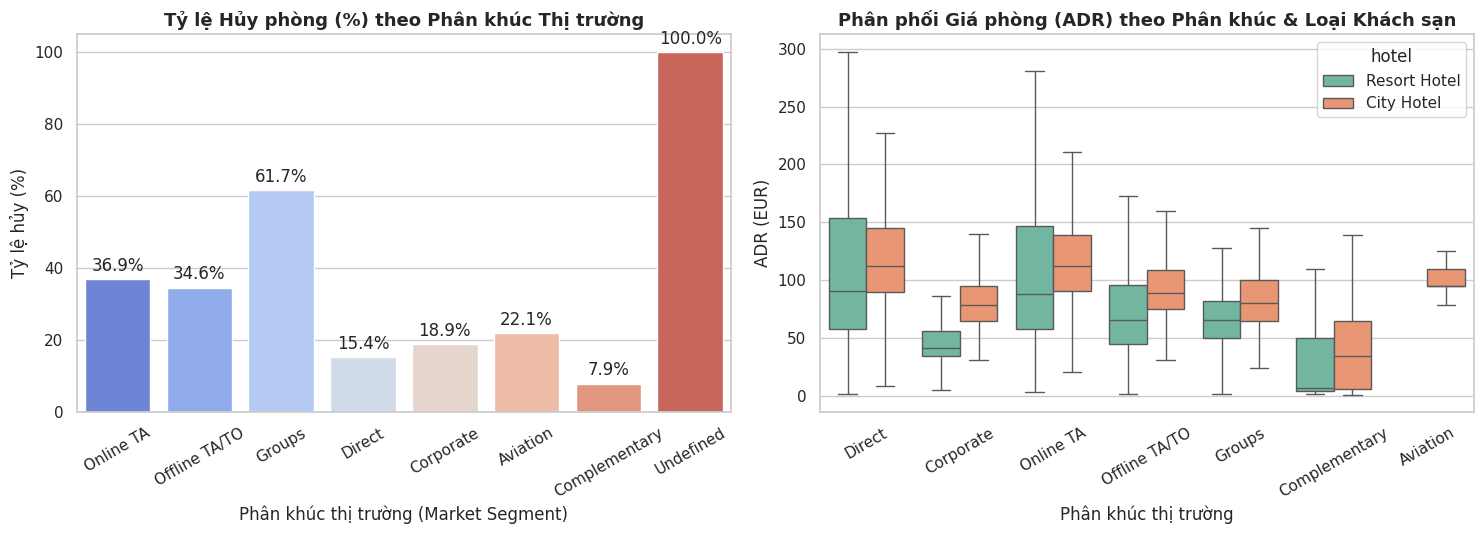

In [7]:
seg_summary = df.groupby('market_segment').agg(
    Tong_don=('is_canceled', 'count'),
    Ty_le_huy_pct=('is_canceled', lambda x: x.mean() * 100),
    ADR_trung_binh=('adr', 'mean'),
    Doanh_thu_uoc_tinh=('estimated_revenue', 'sum')
).sort_values(by='Tong_don', ascending=False)

display(seg_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Tỷ lệ hủy theo phân khúc thị trường
sns.barplot(
    x=seg_summary.index, y=seg_summary['Ty_le_huy_pct'],
    ax=axes[0], palette='coolwarm'
)
axes[0].set_title('Tỷ lệ Hủy phòng (%) theo Phân khúc Thị trường')
axes[0].set_xlabel('Phân khúc thị trường (Market Segment)')
axes[0].set_ylabel('Tỷ lệ hủy (%)')
axes[0].tick_params(axis='x', rotation=30)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.1f%%', padding=3)

# Phân phối ADR theo phân khúc thị trường và loại khách sạn
sns.boxplot(
    data=df_not_canceled, x='market_segment', y='adr', hue='hotel',
    ax=axes[1], showfliers=False
)
axes[1].set_title('Phân phối Giá phòng (ADR) theo Phân khúc & Loại Khách sạn')
axes[1].set_xlabel('Phân khúc thị trường')
axes[1].set_ylabel('ADR (EUR)')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "03_market_segment_analysis.png"), dpi=300)
plt.show()

### 2.4. Khám phá 4 Nhân tố Hành vi Dẫn đến Hủy phòng
Khảo sát tác động của:
1. **Thời gian đặt trước (`lead_time_group`):** Đặt càng xa ngày nhận phòng, rủi ro hủy càng tăng mạnh.
2. **Loại đặt cọc (`deposit_type`):** Nghịch lý phân khúc *Non Refund* (chủ yếu đến từ các đoàn lớn/đại lý đặt giữ chỗ trước ở Bồ Đào Nha nên tỷ lệ hủy thực tế rất cao).
3. **Số lượng yêu cầu đặc biệt (`total_of_special_requests`):** Khách có yêu cầu cụ thể (tầng cao, nôi em bé, view đẹp...) có tỷ lệ hủy thấp hơn hẳn.
4. **Đổi loại phòng (`is_room_changed`) & Khách quay lại (`is_repeated_guest`).**

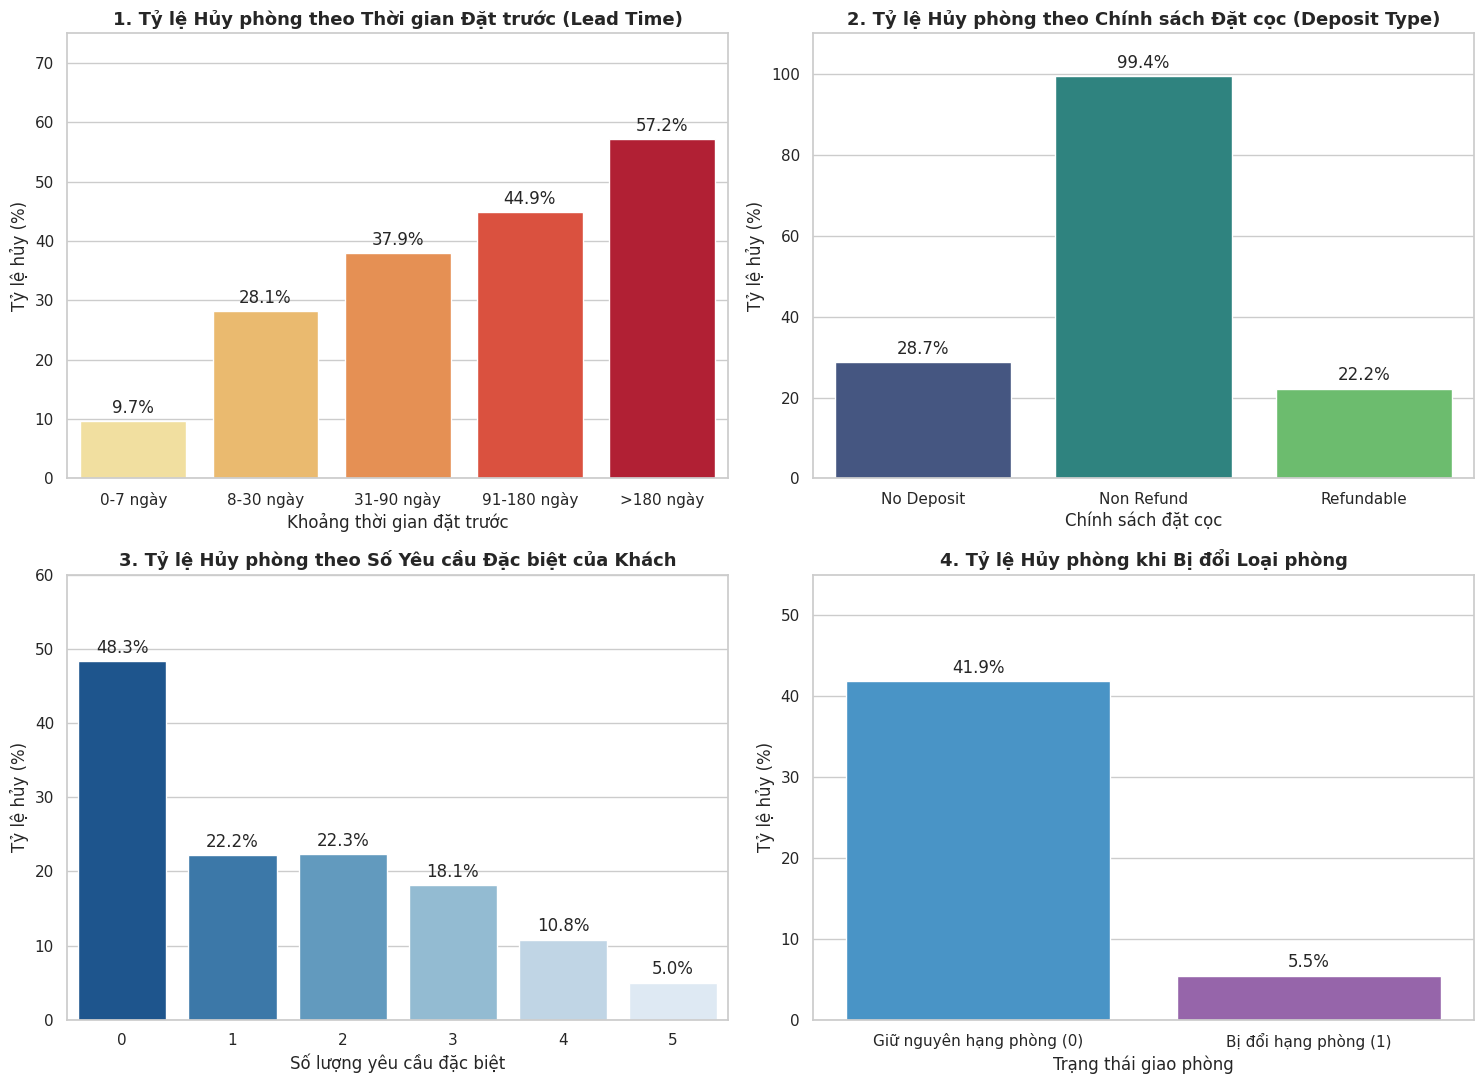

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Tỷ lệ hủy theo nhóm Lead Time
lt_cancel = df.groupby('lead_time_group', observed=False)['is_canceled'].mean() * 100
sns.barplot(x=lt_cancel.index, y=lt_cancel.values, ax=axes[0, 0], palette='YlOrRd')
axes[0, 0].set_title('1. Tỷ lệ Hủy phòng theo Thời gian Đặt trước (Lead Time)')
axes[0, 0].set_xlabel('Khoảng thời gian đặt trước')
axes[0, 0].set_ylabel('Tỷ lệ hủy (%)')
axes[0, 0].set_ylim(0, 75)
for c in axes[0, 0].containers:
    axes[0, 0].bar_label(c, fmt='%.1f%%', padding=3)

# 2. Tỷ lệ hủy theo Loại đặt cọc (Deposit Type)
dep_cancel = df.groupby('deposit_type')['is_canceled'].mean() * 100
sns.barplot(x=dep_cancel.index, y=dep_cancel.values, ax=axes[0, 1], palette='viridis')
axes[0, 1].set_title('2. Tỷ lệ Hủy phòng theo Chính sách Đặt cọc (Deposit Type)')
axes[0, 1].set_xlabel('Chính sách đặt cọc')
axes[0, 1].set_ylabel('Tỷ lệ hủy (%)')
axes[0, 1].set_ylim(0, 110)
for c in axes[0, 1].containers:
    axes[0, 1].bar_label(c, fmt='%.1f%%', padding=3)

# 3. Tỷ lệ hủy theo Số lượng yêu cầu đặc biệt
req_cancel = df.groupby('total_of_special_requests')['is_canceled'].mean() * 100
sns.barplot(x=req_cancel.index, y=req_cancel.values, ax=axes[1, 0], palette='Blues_r')
axes[1, 0].set_title('3. Tỷ lệ Hủy phòng theo Số Yêu cầu Đặc biệt của Khách')
axes[1, 0].set_xlabel('Số lượng yêu cầu đặc biệt')
axes[1, 0].set_ylabel('Tỷ lệ hủy (%)')
axes[1, 0].set_ylim(0, 60)
for c in axes[1, 0].containers:
    axes[1, 0].bar_label(c, fmt='%.1f%%', padding=3)

# 4. Tỷ lệ hủy theo việc Bị đổi hạng phòng (is_room_changed)
rc_cancel = df.groupby('is_room_changed')['is_canceled'].mean() * 100
sns.barplot(
    x=['Giữ nguyên hạng phòng (0)', 'Bị đổi hạng phòng (1)'],
    y=rc_cancel.values, ax=axes[1, 1], palette=['#3498db', '#9b59b6']
)
axes[1, 1].set_title('4. Tỷ lệ Hủy phòng khi Bị đổi Loại phòng')
axes[1, 1].set_xlabel('Trạng thái giao phòng')
axes[1, 1].set_ylabel('Tỷ lệ hủy (%)')
axes[1, 1].set_ylim(0, 55)
for c in axes[1, 1].containers:
    axes[1, 1].bar_label(c, fmt='%.1f%%', padding=3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "04_cancellation_drivers.png"), dpi=300)
plt.show()

### 2.5. Top 10 Quốc gia có Lượng Đặt phòng Lớn nhất & Ma trận Tương quan Biến số

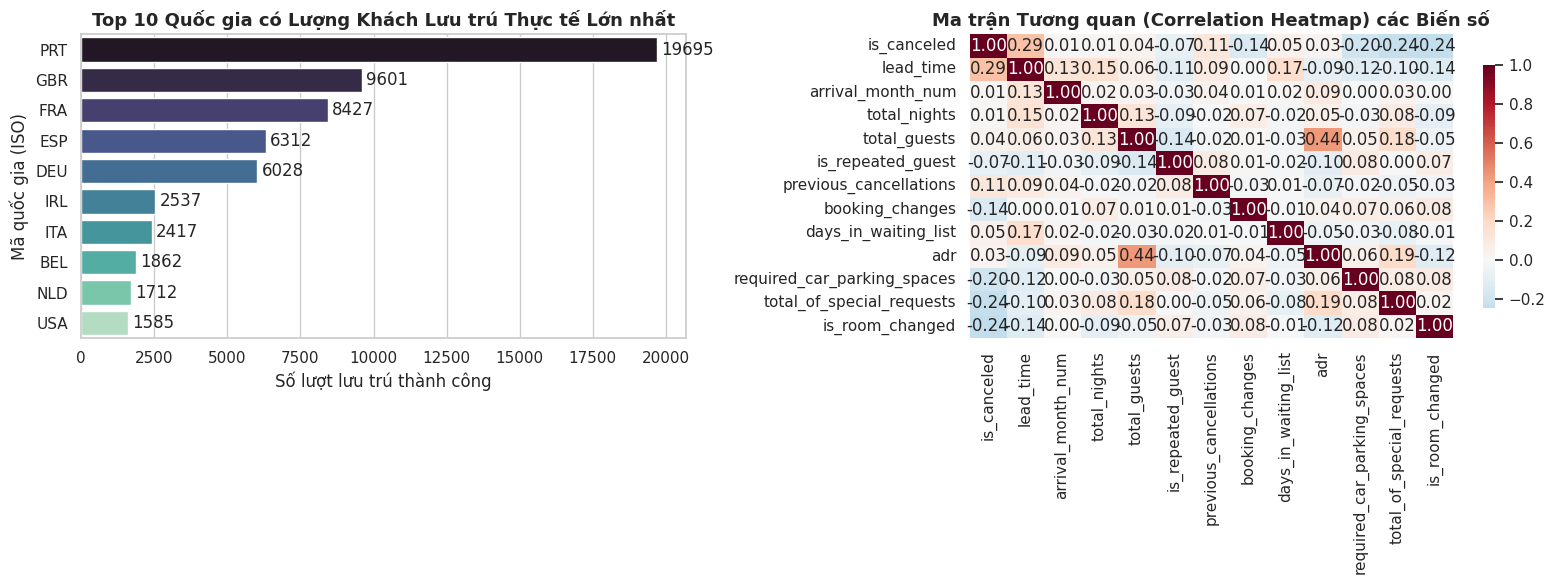

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 quốc gia đặt phòng (đơn không hủy)
top10_countries = df_not_canceled['country'].value_counts().head(10)
sns.barplot(x=top10_countries.values, y=top10_countries.index, ax=axes[0], palette='mako')
axes[0].set_title('Top 10 Quốc gia có Lượng Khách Lưu trú Thực tế Lớn nhất')
axes[0].set_xlabel('Số lượt lưu trú thành công')
axes[0].set_ylabel('Mã quốc gia (ISO)')
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%d', padding=3)

# Ma trận tương quan giữa các biến số chính
num_corr_cols = [
    'is_canceled', 'lead_time', 'arrival_month_num', 'total_nights',
    'total_guests', 'is_repeated_guest', 'previous_cancellations',
    'booking_changes', 'days_in_waiting_list', 'adr',
    'required_car_parking_spaces', 'total_of_special_requests', 'is_room_changed'
]
corr_matrix = df[num_corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[1], cbar_kws={'shrink': 0.8})
axes[1].set_title('Ma trận Tương quan (Correlation Heatmap) các Biến số')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "05_countries_and_correlation.png"), dpi=300)
plt.show()

---
## PHẦN 3 (LÊ ANH KHOA): XÂY DỰNG SCIKIT-LEARN PIPELINE & MÔ HÌNH DỰ ĐOÁN HỦY PHÒNG

### 3.1. Loại bỏ hoàn toàn Data Leakage & Thiết lập tập đặc trưng đầu vào
**Kiểm tra chống rò rỉ dữ liệu:**
- Các cột `reservation_status` (*Canceled, Check-Out, No-Show*) và `reservation_status_date` phản ánh trạng thái sau khi sự kiện hủy đã xảy ra -> **Loại bỏ hoàn toàn**.
- Các cột trung gian dùng cho EDA (`arrival_date_month`, `lead_time_group`, `country`, `company`, `estimated_revenue`) cũng được loại bỏ để tránh trùng lặp thông tin với các biến đã chuẩn hóa (`arrival_month_num`, `lead_time`, `country_grouped`, `has_company`).

In [10]:
# Danh sách biến số đầu vào cho mô hình dự đoán hủy phòng
numeric_features = [
    'lead_time', 'arrival_date_year', 'arrival_month_num', 'arrival_date_week_number',
    'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights',
    'total_nights', 'adults', 'children', 'babies', 'total_guests',
    'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled',
    'booking_changes', 'agent', 'has_company', 'days_in_waiting_list',
    'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'is_room_changed'
]

# Danh sách biến phân loại đầu vào
categorical_features = [
    'hotel', 'meal', 'country_grouped', 'market_segment',
    'distribution_channel', 'reserved_room_type', 'assigned_room_type',
    'deposit_type', 'customer_type'
]

target_col = 'is_canceled'

X = df[numeric_features + categorical_features].copy()
y = df[target_col].copy()

# Kiểm tra chắc chắn không còn cột rò rỉ dữ liệu
leakage_cols = {'reservation_status', 'reservation_status_date'}
assert len(leakage_cols.intersection(set(X.columns))) == 0, "CẢNH BÁO: Phát hiện cột Data Leakage!"

# Chia tập Train / Test (80% / 20%) giữ nguyên tỷ lệ lớp (stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Tập huấn luyện (X_train): {X_train.shape[0]:,} dòng x {X_train.shape[1]} đặc trưng")
print(f"Tập kiểm thử   (X_test) : {X_test.shape[0]:,} dòng x {X_test.shape[1]} đặc trưng")
print("Đã xác nhận: 0 cột Data Leakage trong tập đặc trưng huấn luyện.")

Tập huấn luyện (X_train): 93,918 dòng x 32 đặc trưng
Tập kiểm thử   (X_test) : 23,480 dòng x 32 đặc trưng
Đã xác nhận: 0 cột Data Leakage trong tập đặc trưng huấn luyện.


### 3.2. Đóng gói Preprocessor bằng `ColumnTransformer` & Huấn luyện 3 Mô hình Phân loại
So sánh hiệu năng của 3 thuật toán trong cùng một kiến trúc `Pipeline`:
1. **Logistic Regression** (Mô hình tuyến tính cơ sở - Baseline).
2. **Random Forest Classifier** (Mô hình tổ hợp cây quyết định).
3. **XGBoost Classifier** (Mô hình Gradient Boosting hiệu năng cao).

In [11]:
# Bộ tiền xử lý cho biến số: Điền trung vị + RobustScaler (chống nhiễu ngoại lai)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# Bộ tiền xử lý cho biến phân loại: Điền giá trị phổ biến + OneHotEncoder
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Gộp thành ColumnTransformer thống nhất
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Khởi tạo 3 Pipeline mô hình phân loại
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=20, min_samples_split=5, n_jobs=-1, random_state=42
    ),
    'XGBoost': XGBClassifier(
        n_estimators=300, learning_rate=0.1, max_depth=8,
        subsample=0.8, colsample_bytree=0.8, eval_metric='logloss',
        n_jobs=-1, random_state=42
    )
}

results_list = []
trained_pipelines = {}
roc_data = {}

for name, clf in models.items():
    print(f"Đang huấn luyện Pipeline: {name}...")
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    results_list.append({
        'Mô hình': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, auc)

results_df = pd.DataFrame(results_list).sort_values(by='ROC-AUC', ascending=False)
print("\n=== BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH DỰ ĐOÁN HỦY PHÒNG ===")
display(results_df.style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}',
    'Recall': '{:.4f}', 'F1-Score': '{:.4f}', 'ROC-AUC': '{:.4f}'
}))

Đang huấn luyện Pipeline: Logistic Regression...
Đang huấn luyện Pipeline: Random Forest...
Đang huấn luyện Pipeline: XGBoost...

=== BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH DỰ ĐOÁN HỦY PHÒNG ===


,Mô hình,Accuracy,Precision,Recall,F1-Score,ROC-AUC
2,XGBoost,0.8926,0.8724,0.8357,0.8537,0.9623
1,Random Forest,0.8851,0.8968,0.7836,0.8364,0.9586
0,Logistic Regression,0.8191,0.8129,0.6720,0.7358,0.9015


### 3.3. Trực quan hóa ROC Curve, Confusion Matrix & Top 15 Yếu tố Quan trọng nhất (Feature Importance)

Mô hình tốt nhất được chọn: XGBoost


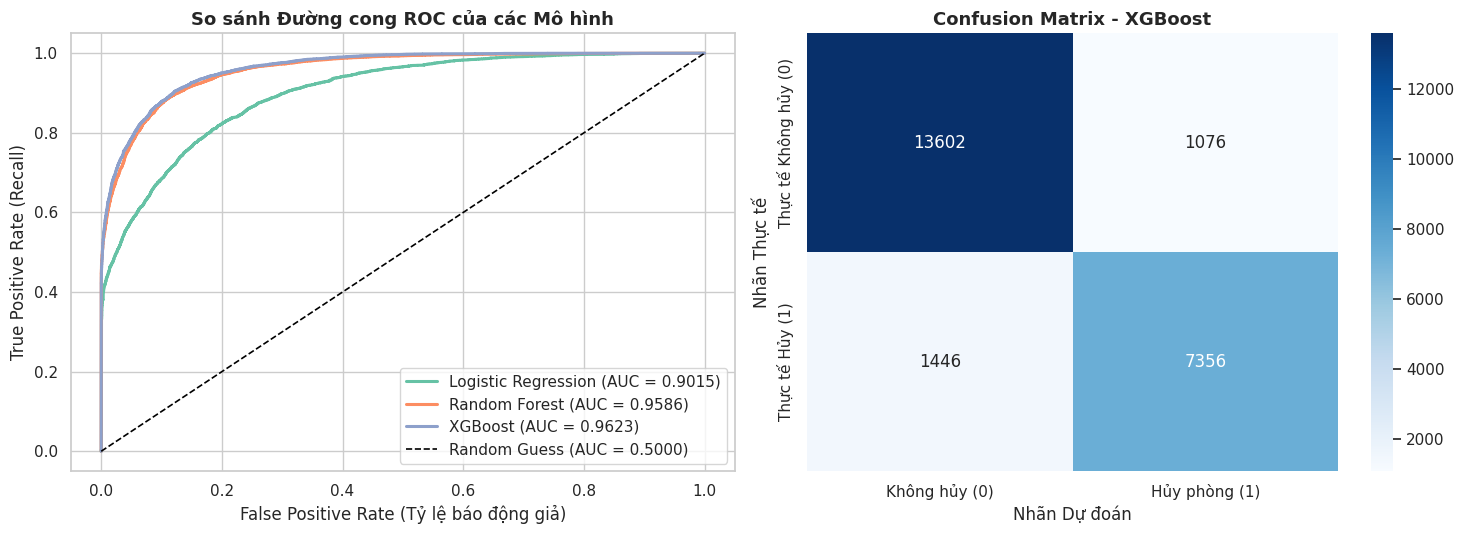


Báo cáo phân loại chi tiết (XGBoost):
               precision    recall  f1-score   support

Không hủy (0)       0.90      0.93      0.92     14678
Hủy phòng (1)       0.87      0.84      0.85      8802

     accuracy                           0.89     23480
    macro avg       0.89      0.88      0.88     23480
 weighted avg       0.89      0.89      0.89     23480



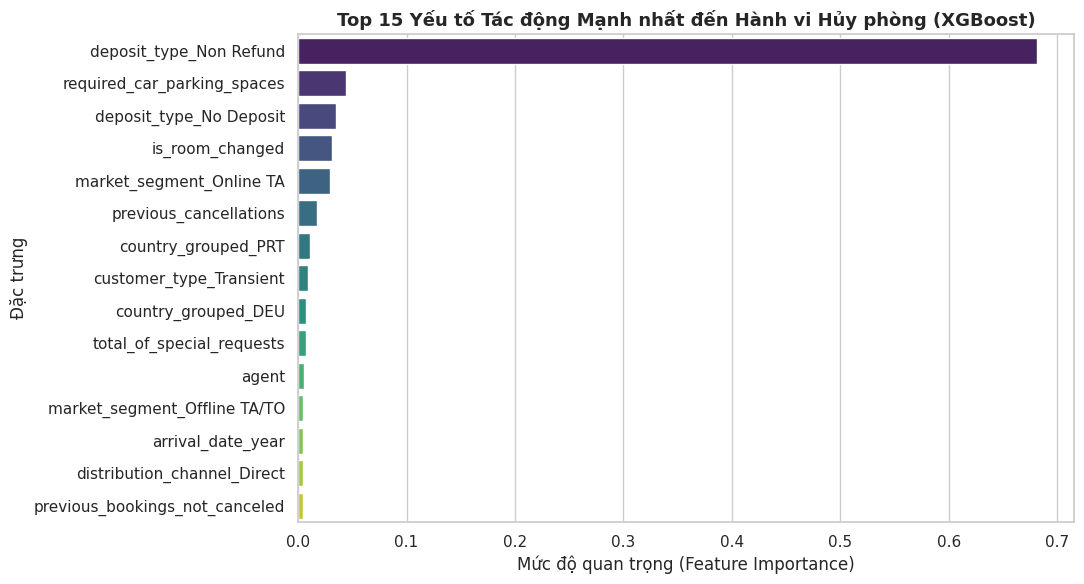

In [12]:
best_model_name = results_df.iloc[0]['Mô hình']
best_cancel_pipeline = trained_pipelines[best_model_name]
print(f"Mô hình tốt nhất được chọn: {best_model_name}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Biểu đồ đường cong ROC-AUC của cả 3 mô hình
for name, (fpr, tpr, auc_val) in roc_data.items():
    axes[0].plot(fpr, tpr, linewidth=2.2, label=f'{name} (AUC = {auc_val:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1.2, label='Random Guess (AUC = 0.5000)')
axes[0].set_title('So sánh Đường cong ROC của các Mô hình')
axes[0].set_xlabel('False Positive Rate (Tỷ lệ báo động giả)')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right')

# 2. Ma trận nhầm lẫn (Confusion Matrix) của mô hình tốt nhất
y_pred_best = best_cancel_pipeline.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
    xticklabels=['Không hủy (0)', 'Hủy phòng (1)'],
    yticklabels=['Thực tế Không hủy (0)', 'Thực tế Hủy (1)']
)
axes[1].set_title(f'Confusion Matrix - {best_model_name}')
axes[1].set_xlabel('Nhãn Dự đoán')
axes[1].set_ylabel('Nhãn Thực tế')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "06_roc_and_confusion_matrix.png"), dpi=300)
plt.show()

print(f"\nBáo cáo phân loại chi tiết ({best_model_name}):")
print(classification_report(y_test, y_pred_best, target_names=['Không hủy (0)', 'Hủy phòng (1)']))

# Trích xuất Top 15 đặc trưng quan trọng nhất từ mô hình tốt nhất
ohe_feature_names = best_cancel_pipeline.named_steps['preprocessor']\
    .named_transformers_['cat']\
    .named_steps['onehot']\
    .get_feature_names_out(categorical_features)

all_feature_names = np.concatenate([numeric_features, ohe_feature_names])
importances = best_cancel_pipeline.named_steps['classifier'].feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(11, 6))
sns.barplot(data=feat_imp_df, x='Importance', y='Feature', palette='viridis')
plt.title(f'Top 15 Yếu tố Tác động Mạnh nhất đến Hành vi Hủy phòng ({best_model_name})')
plt.xlabel('Mức độ quan trọng (Feature Importance)')
plt.ylabel('Đặc trưng')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "07_top15_feature_importance.png"), dpi=300)
plt.show()

---
## PHẦN 4 (LÊ ANH KHOA): MÔ HÌNH DỰ BÁO GIÁ PHÒNG (ADR) & CHIẾN LƯỢC TỐI ƯU DOANH THU

### 4.1. Xây dựng Pipeline Hồi quy Dự báo Giá phòng Trung bình Ngày (`ADR`)
Huấn luyện mô hình **XGBoost Regressor** để định giá phòng tham chiếu (`ADR`) dựa trên loại khách sạn, mùa vụ, thời gian đặt trước, quy mô khách, phân khúc thị trường và hạng phòng.

Đang huấn luyện mô hình dự báo giá phòng (XGBoost Regressor)...
=== KẾT QUẢ MÔ HÌNH DỰ BÁO GIÁ PHÒNG (ADR) ===
- MAE  (Sai số tuyệt đối trung bình) : 9.26 EUR
- RMSE (Sai số toàn phương trung bình): 14.89 EUR
- R2 Score (Độ phù hợp mô hình)       : 0.8975


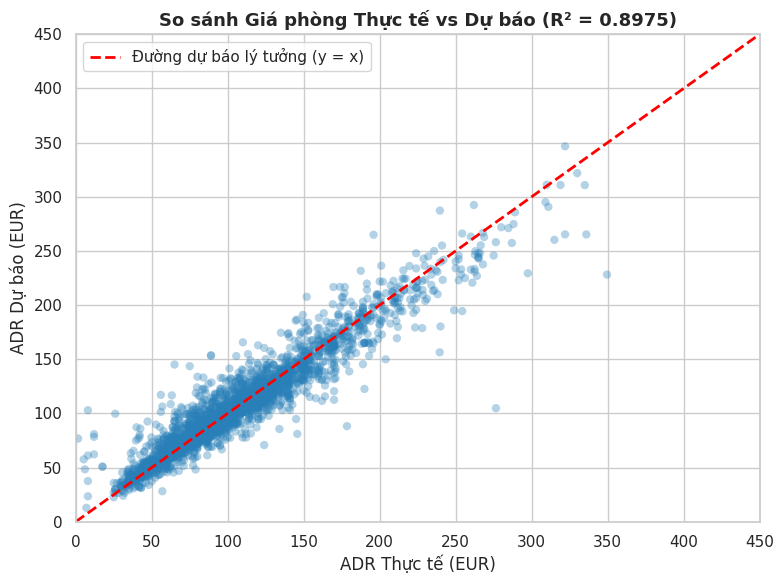

In [13]:
adr_num_features = [
    'lead_time', 'arrival_date_year', 'arrival_month_num', 'arrival_date_week_number',
    'stays_in_weekend_nights', 'stays_in_week_nights', 'total_nights',
    'adults', 'children', 'babies', 'total_guests',
    'is_repeated_guest', 'total_of_special_requests'
]

adr_cat_features = [
    'hotel', 'meal', 'country_grouped', 'market_segment',
    'distribution_channel', 'reserved_room_type', 'customer_type'
]

X_adr = df[adr_num_features + adr_cat_features].copy()
y_adr = df['adr'].copy()

X_adr_train, X_adr_test, y_adr_train, y_adr_test = train_test_split(
    X_adr, y_adr, test_size=0.20, random_state=42
)

adr_preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', RobustScaler())]), adr_num_features),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), adr_cat_features)
    ]
)

adr_pipeline = Pipeline(steps=[
    ('preprocessor', adr_preprocessor),
    ('regressor', XGBRegressor(
        n_estimators=300, learning_rate=0.1, max_depth=8,
        subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42
    ))
])

print("Đang huấn luyện mô hình dự báo giá phòng (XGBoost Regressor)...")
adr_pipeline.fit(X_adr_train, y_adr_train)

y_adr_pred = adr_pipeline.predict(X_adr_test)
mae = mean_absolute_error(y_adr_test, y_adr_pred)
rmse = np.sqrt(mean_squared_error(y_adr_test, y_adr_pred))
r2 = r2_score(y_adr_test, y_adr_pred)

print(f"=== KẾT QUẢ MÔ HÌNH DỰ BÁO GIÁ PHÒNG (ADR) ===")
print(f"- MAE  (Sai số tuyệt đối trung bình) : {mae:.2f} EUR")
print(f"- RMSE (Sai số toàn phương trung bình): {rmse:.2f} EUR")
print(f"- R2 Score (Độ phù hợp mô hình)       : {r2:.4f}")

# Vẽ biểu đồ Actual vs Predicted ADR
plt.figure(figsize=(8, 6))
sample_idx = np.random.RandomState(42).choice(len(y_adr_test), size=min(3000, len(y_adr_test)), replace=False)
plt.scatter(y_adr_test.iloc[sample_idx], y_adr_pred[sample_idx], alpha=0.35, color='#2980b9', edgecolor='none')
plt.plot([0, 450], [0, 450], 'r--', linewidth=2, label='Đường dự báo lý tưởng (y = x)')
plt.xlim(0, 450)
plt.ylim(0, 450)
plt.title(f'So sánh Giá phòng Thực tế vs Dự báo (R² = {r2:.4f})')
plt.xlabel('ADR Thực tế (EUR)')
plt.ylabel('ADR Dự báo (EUR)')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "08_adr_actual_vs_predicted.png"), dpi=300)
plt.show()

### 4.2. Phân tầng Rủi ro Hủy phòng & Tính toán Tỷ lệ Đặt vượt Công suất (Overbooking Buffer)
Ứng dụng xác suất hủy phòng dự báo $P(\text{cancel})$ từ mô hình tốt nhất trên tập kiểm thử (`X_test`) để:
1. Phân loại các đơn đặt phòng thành 3 nhóm rủi ro: **Thấp (< 30%)**, **Trung bình (30% – 60%)**, **Cao (> 60%)**.
2. Tính toán **Doanh thu gặp rủi ro (Revenue at Risk)** và **Ngưỡng Overbooking an toàn** (bằng 70% tỷ lệ hủy kỳ vọng của từng tháng để tránh tình trạng vượt quá công suất phòng thực tế).

In [14]:
# Dự báo xác suất hủy phòng trên tập kiểm thử
test_analysis = X_test.copy()
test_analysis['actual_canceled'] = y_test.values
test_analysis['cancel_prob'] = best_cancel_pipeline.predict_proba(X_test)[:, 1]
test_analysis['est_revenue'] = test_analysis['adr'] * test_analysis['total_nights']
test_analysis['expected_revenue_at_risk'] = test_analysis['est_revenue'] * test_analysis['cancel_prob']

# Phân tầng rủi ro
test_analysis['risk_tier'] = pd.cut(
    test_analysis['cancel_prob'],
    bins=[-0.01, 0.30, 0.60, 1.01],
    labels=['1. Rủi ro Thấp (<30%)', '2. Rủi ro Trung bình (30-60%)', '3. Rủi ro Cao (>60%)']
)

risk_summary = test_analysis.groupby('risk_tier', observed=False).agg(
    So_luong_don=('actual_canceled', 'count'),
    Ty_le_huy_thuc_te_pct=('actual_canceled', lambda x: x.mean() * 100),
    Tong_doanh_thu_EUR=('est_revenue', 'sum'),
    Doanh_thu_rui_ro_EUR=('expected_revenue_at_risk', 'sum')
)
print("=== BẢNG PHÂN TẦNG RỦI RO HỦY PHÒNG & DOANH THU GẶP RỦI RO (TRÊN TẬP TEST) ===")
display(risk_summary.round(2))

# Bảng đề xuất tỷ lệ Overbooking an toàn theo từng tháng cho City Hotel & Resort Hotel
overbooking_table = test_analysis.groupby(['hotel', 'arrival_month_num']).agg(
    Xac_suat_huy_TB_pct=('cancel_prob', lambda x: x.mean() * 100),
    ADR_TB_EUR=('adr', 'mean')
).reset_index()

# Hệ số an toàn 0.70 nhằm hạn chế rủi ro phải từ chối khách khi tất cả đều đến nhận phòng
overbooking_table['De_xuat_Overbooking_pct'] = (overbooking_table['Xac_suat_huy_TB_pct'] * 0.70).round(1)

print("\n=== ĐỀ XUẤT NGƯỠNG OVERBOOKING AN TOÀN THEO THÁNG & LOẠI KHÁCH SẠN ===")
display(overbooking_table.pivot(index='arrival_month_num', columns='hotel', values='De_xuat_Overbooking_pct'))

=== BẢNG PHÂN TẦNG RỦI RO HỦY PHÒNG & DOANH THU GẶP RỦI RO (TRÊN TẬP TEST) ===


,So_luong_don,Ty_le_huy_thuc_te_pct,Tong_doanh_thu_EUR,Doanh_thu_rui_ro_EUR
risk_tier,,,,
1. Rủi ro Thấp (<30%),13160,5.02,"4,476,810.72","261,134.52"
2. Rủi ro Trung bình (30-60%),2750,46.25,"1,176,589.89","523,337.42"
3. Rủi ro Cao (>60%),7570,90.74,"2,905,118.13","2,521,441.19"



=== ĐỀ XUẤT NGƯỠNG OVERBOOKING AN TOÀN THEO THÁNG & LOẠI KHÁCH SẠN ===


hotel,City Hotel,Resort Hotel
arrival_month_num,,
1,27.20,10.30
2,27.50,16.70
3,25.40,14.70
4,33.60,19.00
5,32.30,18.80
6,31.30,22.40
7,28.10,22.40
8,27.80,22.50
9,30.40,23.40


---
## PHẦN 5: LƯU TRỮ PIPELINE & TỔNG HỢP KHUYẾN NGHỊ CHIẾN LƯỢC

Lưu toàn bộ các mô hình đã đóng gói (`Pipeline`) ra file `.joblib` trong thư mục `DAN/outputs` để sẵn sàng tích hợp vào hệ thống quản lý khách sạn (PMS) hoặc giao diện demo khi bảo vệ đồ án.

In [15]:
# Lưu các Pipeline đã huấn luyện
cancel_model_path = os.path.join(OUTPUT_DIR, "best_cancellation_pipeline.joblib")
adr_model_path = os.path.join(OUTPUT_DIR, "best_adr_pipeline.joblib")

joblib.dump(best_cancel_pipeline, cancel_model_path)
joblib.dump(adr_pipeline, adr_model_path)

print(f"Đã lưu mô hình dự đoán hủy phòng tại: {cancel_model_path}")
print(f"Đã lưu mô hình dự báo giá ADR tại   : {adr_model_path}")

# Demo dự đoán thử trên 3 đơn đặt phòng thực tế từ tập Test
sample_bookings = X_test.iloc[:3].copy()
sample_preds = best_cancel_pipeline.predict_proba(sample_bookings)[:, 1]
sample_adr_preds = adr_pipeline.predict(sample_bookings[adr_num_features + adr_cat_features])

demo_df = sample_bookings[['hotel', 'lead_time', 'market_segment', 'deposit_type', 'adr']].copy()
demo_df['Xac_suat_huy_%'] = (sample_preds * 100).round(2)
demo_df['ADR_goi_y_EUR'] = sample_adr_preds.round(2)

print("\n=== DEMO DỰ BÁO TRÊN 3 ĐƠN ĐẶT PHÒNG MẪU ===")
display(demo_df)

print("""
================================================================================
TỔNG HỢP KHUYẾN NGHỊ CHIẾN LƯỢC TỐI ƯU DOANH THU & GIẢM HỦY PHÒNG (ĐT08)
================================================================================
1. KIỂM SOÁT RỦI RO ĐẶT SỚM (LEAD TIME > 90 NGÀY):
   - Các đơn đặt trước trên 90 ngày (đặc biệt qua kênh Online TA & Groups) có tỷ lệ
     hủy rất cao. Hệ thống tự động gắn cờ nhóm Rủi ro Cao (>60%) để gửi email/tin
     nhắn xác nhận lại trước ngày nhận phòng 14 ngày và 3 ngày.

2. CHÍNH SÁCH ĐẶT CỌC & PHÂN KHÚC KHÁCH HÀNG:
   - Áp dụng mức đặt cọc linh hoạt (Partial Deposit / Non-refundable ưu đãi giá)
     cho các đơn đặt đoàn lớn hoặc đặt vào mùa cao điểm (tháng 7 - tháng 8).
   - Khuyến khích khách chọn gói dịch vụ đi kèm hoặc ghi nhận yêu cầu đặc biệt
     ngay lúc đặt phòng vì nhóm khách này có tỷ lệ giữ phòng cao vượt trội.

3. CHIẾN LƯỢC ĐỊNH GIÁ ĐỘNG (DYNAMIC PRICING) THEO MÙA & LOẠI KHÁCH SẠN:
   - Resort Hotel có biên độ ADR biến động rất mạnh theo mùa (tăng vọt vào tháng 7-8
     và giảm sâu vào tháng 11-1). Cần đẩy mạnh gói combo nghỉ dưỡng dài ngày kèm
     dịch vụ ăn uống (HB/FB) vào mùa thấp điểm để duy trì công suất phòng.
   - City Hotel có nhu cầu ổn định quanh năm hơn; tận dụng mô hình dự báo ADR để
     điều chỉnh giá linh hoạt theo từng phân khúc khách công tác (Corporate) và du lịch.

4. VẬN HÀNH OVERBOOKING CÓ KIỂM SOÁT:
   - Áp dụng ngưỡng đặt vượt công suất an toàn (bằng ~70% xác suất hủy dự báo theo
     từng tháng) giúp bù đắp tổn thất doanh thu do hủy phòng giờ chót mà vẫn đảm bảo
     trải nghiệm nhận phòng của khách hàng.
================================================================================
""")

Đã lưu mô hình dự đoán hủy phòng tại: /content/drive/MyDrive/NTTU/NH 2026-2027/HK1 2026-2027/Chuyên đề chuyên sâu Kỹ thuật CNTT 1/DAN/outputs/best_cancellation_pipeline.joblib
Đã lưu mô hình dự báo giá ADR tại   : /content/drive/MyDrive/NTTU/NH 2026-2027/HK1 2026-2027/Chuyên đề chuyên sâu Kỹ thuật CNTT 1/DAN/outputs/best_adr_pipeline.joblib

=== DEMO DỰ BÁO TRÊN 3 ĐƠN ĐẶT PHÒNG MẪU ===


,hotel,lead_time,market_segment,deposit_type,adr,Xac_suat_huy_%,ADR_goi_y_EUR
55143,City Hotel,73,Online TA,No Deposit,140.40,25.06,141.67
3094,Resort Hotel,27,Online TA,No Deposit,48.00,17.14,45.43
41928,City Hotel,18,Online TA,No Deposit,93.00,0.00,97.25



TỔNG HỢP KHUYẾN NGHỊ CHIẾN LƯỢC TỐI ƯU DOANH THU & GIẢM HỦY PHÒNG (ĐT08)
1. KIỂM SOÁT RỦI RO ĐẶT SỚM (LEAD TIME > 90 NGÀY):
   - Các đơn đặt trước trên 90 ngày (đặc biệt qua kênh Online TA & Groups) có tỷ lệ
     hủy rất cao. Hệ thống tự động gắn cờ nhóm Rủi ro Cao (>60%) để gửi email/tin
     nhắn xác nhận lại trước ngày nhận phòng 14 ngày và 3 ngày.

2. CHÍNH SÁCH ĐẶT CỌC & PHÂN KHÚC KHÁCH HÀNG:
   - Áp dụng mức đặt cọc linh hoạt (Partial Deposit / Non-refundable ưu đãi giá)
     cho các đơn đặt đoàn lớn hoặc đặt vào mùa cao điểm (tháng 7 - tháng 8).
   - Khuyến khích khách chọn gói dịch vụ đi kèm hoặc ghi nhận yêu cầu đặc biệt
     ngay lúc đặt phòng vì nhóm khách này có tỷ lệ giữ phòng cao vượt trội.

3. CHIẾN LƯỢC ĐỊNH GIÁ ĐỘNG (DYNAMIC PRICING) THEO MÙA & LOẠI KHÁCH SẠN:
   - Resort Hotel có biên độ ADR biến động rất mạnh theo mùa (tăng vọt vào tháng 7-8
     và giảm sâu vào tháng 11-1). Cần đẩy mạnh gói combo nghỉ dưỡng dài ngày kèm
     dịch vụ ăn uống (HB/FB) vào mùa thấp điể